# Structure comparison — does the input fold change the GNN's prediction?

One checkpoint, one set of 15 human-proteome peptides, **three different ways of
obtaining the backbone** the graph is built from. Everything else is held fixed, so a
difference between columns is a difference in the structure and nothing else.

| Key | Dataset | How the backbone was obtained |
|---|---|---|
| `esm_segment` | `data/proteome_sanity_test/` | ESMFold run on the **isolated peptide** — the pipeline's normal behaviour |
| `esm_whole` | `data/proteome_sanity_test_wholeprot/` | ESMFold run on the **whole parent protein**, then the peptide's residue range excised |
| `afdb_native` | `data/proteome_sanity_test_afdb/` | **AlphaFold DB** (v6) model of the parent, same range excised |

The question this set was built to answer: ESMFold given a 12-residue fragment with no
context produced a polyproline-II rod for `PPP1CB`, whose Cα(i,i+3) = 9.25 Å sits just
outside the 8 Å contact cutoff — so its graph collapsed to `{(i, i±1), (i, i±2)}` and
carried no structural information at all. The native fold is a helix. The two
context-aware columns are the control: if structure matters to this model, giving it
the right fold should move the score.

## Two provenance notes

- **The graph here is the graph the model saw.** The edge set is rebuilt with
  `gnn_minimal.core.data_utils.compute_edges`, the same function `PeptideGraphDataset`
  calls at access time, rather than a local re-implementation of the 8 Å rule. Nothing
  is cached on disk — no `.pt` files exist under `data/` — so this is an exact replay.
- **σ is the logit margin** `logit_AMP − logit_nonAMP`, and the call is
  `prediction = p_amp ≥ 0.5`. Where that lands on the σ axis depends on the calibration:
  these runs are **temperature-scaled**, which has no intercept, so the boundary is
  σ = 0. The threshold is read from the checkpoint with
  `gnn_minimal.core.calibration.decision_margin` rather than assumed — the same
  structures scored under this checkpoint's Platt file put it at +0.78, and the section
  *Calibration is not neutral here* below shows what that one change does to the
  conclusions.

## Reproducing the runs

All three were scored with the **same** checkpoint — the schema-3 GAT + QSAR-12 model,
trained 2026-11-16 and since promoted from `results/gnn_models/run_20261116_183743/gat_QSAR/`
to `checkpoints/gnn/gnn_scaled_combined_dataset/`. The run manifests still record the old
path, so the cell below matches the checkpoint by **SHA-256** instead and will keep
working wherever the directory is moved to next.

```bash
for d in data/proteome_sanity_test data/proteome_sanity_test_wholeprot data/proteome_sanity_test_afdb; do
  python -m sequence_analysis -i $d/sequences.csv --model gnn \
      --gnn-model checkpoints/gnn/gnn_scaled_combined_dataset --fitting temperature
done
```

`--fitting temperature` is what the default cascade would pick anyway now that
`gnn_temperature_scaling` exists beside the model, but it is passed explicitly so the
manifest records it and the loader below can tell these runs apart from the earlier
Platt-calibrated ones, which are still on disk in the same `results/runs/` trees.

The `esm_whole` run is also copied to
`data/proteome_sanity_test/results/runs/whole-protein-2026-11-18_01-33/` so it sits beside
the run it is the counterfactual for; the two copies are the same CSV and the loader
de-duplicates on the manifest's input path.

In [12]:
from __future__ import annotations

import hashlib
import json
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from scipy.stats import gaussian_kde


def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for path in (here, *here.parents):
        if (path / "sequence_analysis").is_dir() and (path / "checkpoints").is_dir():
            return path
    raise FileNotFoundError("Could not locate the repository root.")


ROOT = find_repo_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# The graph-construction rule and the dihedral convention are read from gnn_minimal
# rather than restated here, so this notebook cannot drift from the model's own view of
# a structure. gnn_minimal has no __init__.py; it imports as a namespace package.
from gnn_minimal.core.calibration import (  # noqa: E402
    decision_margin, describe_calibration, prob_amp, resolve_calibration,
)
from gnn_minimal.core.data_utils import compute_edges, parse_pdb  # noqa: E402
from gnn_minimal.pipeline.features import compute_dihedral  # noqa: E402

DISTANCE_THRESHOLD = 8.0  # core/data_utils.py default
CHECKPOINT = ROOT / "checkpoints" / "gnn" / "gnn_scaled_combined_dataset"

SOURCE_ORDER = ["esm_segment", "esm_whole", "afdb_native"]
SOURCE_DIR = {
    "esm_segment": ROOT / "data" / "proteome_sanity_test",
    "esm_whole": ROOT / "data" / "proteome_sanity_test_wholeprot",
    "afdb_native": ROOT / "data" / "proteome_sanity_test_afdb",
}
SOURCE_LABEL = {
    "esm_segment": "ESMFold, peptide alone",
    "esm_whole": "ESMFold, whole protein",
    "afdb_native": "AlphaFold DB, native",
}
SOURCE_SHORT = {"esm_segment": "ESM-seg", "esm_whole": "ESM-whole", "afdb_native": "AFDB"}

# Categorical slots 1-3 of the documented default palette, in fixed order. These three
# are the pre-validated all-pairs subset (worst-pair CVD dE 9.2, normal-vision 24.0 on a
# light surface), which is what a scatter and a small-multiple grid need.
SOURCE_COLOR = {"esm_segment": "#2a78d6", "esm_whole": "#eb6834", "afdb_native": "#1baf7a"}
SOURCE_MARKER = {"esm_segment": "o", "esm_whole": "s", "afdb_native": "^"}

INK, INK_2, INK_3 = "#0b0b0b", "#52514e", "#8f8d87"
SURFACE, GRID = "#ffffff", "#e7e5e0"
SEQ_CMAP = LinearSegmentedColormap.from_list("blues_1hue", ["#eaf2fc", "#2a78d6", "#15396a"])

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": INK_3, "axes.labelcolor": INK, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlelocation": "left",
    "axes.titleweight": "semibold", "axes.titlesize": 11, "axes.labelsize": 10,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "grid.color": GRID, "grid.linewidth": 0.8, "legend.frameon": False,
    "legend.fontsize": 9, "font.size": 10, "figure.dpi": 110,
})
pd.set_option("display.width", 150, "display.max_columns", 50)

In [13]:
def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


CHECKPOINT_SHA = sha256(CHECKPOINT / "gnn_model.pt")
FITTING = "temperature"

# The threshold is the calibration's own P = 0.5 crossing, not an assumed 0: temperature
# scaling puts it at 0, Platt at -intercept/coef. Both files sit in this checkpoint.
METHOD, PAYLOAD = resolve_calibration(CHECKPOINT, FITTING)
SIGMA_THRESHOLD = decision_margin(METHOD, PAYLOAD)
PLATT_METHOD, PLATT_PAYLOAD = resolve_calibration(CHECKPOINT, "platt")
PLATT_THRESHOLD = decision_margin(PLATT_METHOD, PLATT_PAYLOAD)


def resolve_run(source: str, fitting: str = FITTING) -> Path:
    """Newest completed run for this source, this checkpoint and this calibration.

    Runs for several datasets live under one results/runs tree once a run is copied there,
    so the manifest's input path is the discriminator; the checkpoint is matched by hash
    because the recorded path is stale, and `fitting` separates runs that differ only in
    how the margins were turned into probabilities.
    """
    wanted = (SOURCE_DIR[source] / "sequences.csv").resolve()
    found: list[Path] = []
    for directory in SOURCE_DIR.values():
        for manifest_path in sorted((directory / "results" / "runs").glob("*/run_manifest.json")):
            manifest = json.loads(manifest_path.read_text())
            if manifest.get("status") != "completed":
                continue
            inputs = manifest.get("inputs", {})
            if Path(inputs.get("sequences", {}).get("path", "")) != wanted:
                continue
            if manifest["model"]["files"].get("gnn_model", {}).get("sha256") != CHECKPOINT_SHA:
                continue
            if manifest.get("config", {}).get("effective", {}).get("fitting") != fitting:
                continue
            found.append(manifest_path.parent)
    if not found:
        raise FileNotFoundError(
            f"No completed {fitting} run for {source} with checkpoint {CHECKPOINT.name}.")
    return sorted(found, key=lambda p: json.loads((p / "run_manifest.json").read_text())["created_at_utc"])[-1]


RUN_DIR = {source: resolve_run(source) for source in SOURCE_ORDER}
for source in SOURCE_ORDER:
    print(f"  {source:<12} {RUN_DIR[source].relative_to(ROOT)}")
print(f"\n  checkpoint      {CHECKPOINT.relative_to(ROOT)}  (sha {CHECKPOINT_SHA[:12]}…)")
print(f"  calibration     {describe_calibration(METHOD, PAYLOAD)}")
print(f"  fit on          {Path(PAYLOAD['val_source']).relative_to(ROOT)}  (n = {PAYLOAD['n_calib']})")
print(f"  also on disk    {describe_calibration(PLATT_METHOD, PLATT_PAYLOAD)}")

  esm_segment  data/proteome_sanity_test/results/runs/2026-11-18_10-42
  esm_whole    data/proteome_sanity_test_wholeprot/results/runs/2026-11-18_10-42
  afdb_native  data/proteome_sanity_test_afdb/results/runs/2026-11-18_10-42

  checkpoint      checkpoints/gnn/gnn_scaled_combined_dataset  (sha a4ae2e50cfce…)
  calibration     temperature-scaled P(AMP) (T=0.559, P=0.5 at margin 0.000)
  fit on          data/training/expanded_amps_presplit/expanded_filtered_validation.csv  (n = 320)
  also on disk    Platt-scaled P(AMP) (coef=1.612, intercept=-1.254, P=0.5 at margin 0.778)


## Loading

Per peptide and per source: the prediction row, the geometric feature row the pipeline
wrote, and a set of structure measurements recomputed here from the PDB.

- **`lr_edges`** — contacts with `|i − j| ≥ 3` inside the 8 Å cutoff. The number of edges
  the graph has *beyond* the trivial chain. `max_sep` ≤ 2 means the graph is a width-2
  path and holds no fold information.
- **`ca_i4`** — mean Cα(i, i+4). ≈ 6.2 Å in an α-helix, ≈ 12–13 Å fully extended.
- **`hb_i4` / `hb_i3` / `hb_far`** — backbone H-bonds by sequence offset under the
  Kabsch–Sander (1983) electrostatic criterion, which is the one DSSP applies:
  `E = 0.084·(1/r_ON + 1/r_CH − 1/r_OH − 1/r_CN)·332`, H-bond if `E < −0.5` kcal/mol.
  Two or more `i→i+4` bonds is what makes DSSP say H.

The H-bond term is here because `fraction_sheet` cannot be trusted: `mkdssp` is not
installed, so `extract_secondary_structure` silently falls back to `phi_psi`, a
Ramachandran box test with no H-bonding term at all. `ss_method` reads `phi_psi` for
every row of every dataset in the repo.

In [14]:
THREE_TO_ONE = {
    "ALA": "A", "ARG": "R", "ASN": "N", "ASP": "D", "CYS": "C", "GLN": "Q", "GLU": "E",
    "GLY": "G", "HIS": "H", "ILE": "I", "LEU": "L", "LYS": "K", "MET": "M", "PHE": "F",
    "PRO": "P", "SER": "S", "THR": "T", "TRP": "W", "TYR": "Y", "VAL": "V",
}


def backbone(pdb_path: Path) -> list[dict]:
    """Per-residue backbone atoms in file order, plus the B-factor column (pLDDT)."""
    residues: dict[int, dict] = {}
    order: list[int] = []
    for line in pdb_path.read_text().splitlines():
        if not line.startswith("ATOM"):
            continue
        number = int(line[22:26])
        if number not in residues:
            residues[number] = {"aa": THREE_TO_ONE.get(line[17:20].strip(), "X"),
                                "plddt": float(line[60:66])}
            order.append(number)
        residues[number][line[12:16].strip()] = np.array(
            [float(line[30:38]), float(line[38:46]), float(line[46:54])])
    return [residues[number] for number in order]


def kabsch_sander_hbonds(residues: list[dict]) -> dict[tuple[int, int], float]:
    """Backbone H-bonds C=O(i) -> N-H(j) by the DSSP energy criterion.

    Kabsch W, Sander C. Biopolymers 1983;22:2577-2637.
    E = 0.084*(1/r_ON + 1/r_CH - 1/r_OH - 1/r_CN)*332 kcal/mol, bonded if E < -0.5.
    """
    amide_h: dict[int, np.ndarray] = {}
    for j in range(1, len(residues)):
        if residues[j]["aa"] == "P":  # proline has no amide H
            continue
        c_prev, o_prev = residues[j - 1].get("C"), residues[j - 1].get("O")
        if c_prev is None or o_prev is None or "N" not in residues[j]:
            continue
        direction = c_prev - o_prev
        amide_h[j] = residues[j]["N"] + direction / np.linalg.norm(direction)

    bonds: dict[tuple[int, int], float] = {}
    for i, residue in enumerate(residues):
        if "C" not in residue or "O" not in residue:
            continue
        for j, hydrogen in amide_h.items():
            if abs(i - j) < 2:
                continue
            energy = 0.084 * 332 * (
                1 / np.linalg.norm(residue["O"] - residues[j]["N"])
                + 1 / np.linalg.norm(residue["C"] - hydrogen)
                - 1 / np.linalg.norm(residue["O"] - hydrogen)
                - 1 / np.linalg.norm(residue["C"] - residues[j]["N"])
            )
            if energy < -0.5:
                bonds[(i, j)] = energy
    return bonds


def dihedrals(residues: list[dict]) -> pd.DataFrame:
    """phi/psi in degrees for residues 2..n-1, the ones features.py can compute."""
    rows = []
    for i in range(1, len(residues) - 1):
        previous, current, following = residues[i - 1], residues[i], residues[i + 1]
        if any(key not in current for key in ("N", "CA", "C")) or "C" not in previous or "N" not in following:
            continue
        rows.append({
            "residue": i + 1,
            "aa": current["aa"],
            "phi": np.degrees(compute_dihedral(previous["C"], current["N"], current["CA"], current["C"])),
            "psi": np.degrees(compute_dihedral(current["N"], current["CA"], current["C"], following["N"])),
            "plddt": current["plddt"],
        })
    return pd.DataFrame(rows)


def structure_metrics(pdb_path: Path) -> dict:
    _, ca_coords, _ = parse_pdb(str(pdb_path))
    n = len(ca_coords)
    edge_index, _ = compute_edges(ca_coords, DISTANCE_THRESHOLD)
    separations = (edge_index[0] - edge_index[1]).abs()
    distances = np.linalg.norm(ca_coords[:, None] - ca_coords[None, :], axis=-1)
    contact = (distances < DISTANCE_THRESHOLD) & ~np.eye(n, dtype=bool)
    offsets = np.abs(np.subtract.outer(np.arange(n), np.arange(n)))
    bonds = kabsch_sander_hbonds(backbone(pdb_path))
    contour = np.linalg.norm(np.diff(ca_coords, axis=0), axis=1).sum()
    return {
        "n": n,
        "edges": int(edge_index.shape[1]),
        "max_sep": int(separations.max()),
        "mean_degree": float(contact.sum(axis=1).mean()),
        "lr_edges": int((np.triu(contact, 1) & (offsets >= 3)).sum()),
        "ca_i4": float(np.mean([np.linalg.norm(ca_coords[k + 4] - ca_coords[k]) for k in range(n - 4)])),
        "straightness": float(np.linalg.norm(ca_coords[-1] - ca_coords[0]) / contour),
        "hb_i4": int(sum(1 for i, j in bonds if j - i == 4)),
        "hb_i3": int(sum(1 for i, j in bonds if j - i == 3)),
        "hb_far": int(sum(1 for i, j in bonds if abs(j - i) >= 5)),
    }


GEO_KEEP = ["plddt_mean", "fraction_helix", "fraction_sheet", "fraction_coil", "ss_method",
            "radius_gyration", "torsion_std"]


def load_source(source: str) -> pd.DataFrame:
    directory = SOURCE_DIR[source]
    predictions = pd.read_csv(RUN_DIR[source] / "sequence_predictions.csv")
    geometric = pd.read_csv(directory / "generated" / "geometric_features.csv").set_index("peptide_id")
    rows = []
    for row in predictions.itertuples():
        pdb_path = directory / "generated" / "structures" / f"{row.id}.pdb"
        record = {"source": source, "id": row.id, "label": int(row.label),
                  "sigma": float(row.sigma), "p_amp": float(row.p_amp),
                  "prediction": int(row.prediction), "sequence": row.sequence}
        record.update(structure_metrics(pdb_path))
        record.update(geometric.loc[row.id, GEO_KEEP].to_dict())
        rows.append(record)
    return pd.DataFrame(rows)


frame = pd.concat([load_source(source) for source in SOURCE_ORDER], ignore_index=True)
frame["source"] = pd.Categorical(frame["source"], SOURCE_ORDER, ordered=True)
frame["correct"] = (frame["prediction"] == 1) == (frame["label"] == 1)

# One of the 15 is missing from esm_whole, so every cross-source statistic below is on
# the intersection. CSV order is kept: it is the order sequences.csv lists the peptides.
csv_order = [i for i in frame.loc[frame["source"] == "esm_segment", "id"]]
COMMON = [i for i in csv_order if all((frame[frame["source"] == s]["id"] == i).any() for s in SOURCE_ORDER)]
common = frame[frame["id"].isin(COMMON)].copy()

print(f"rows {len(frame)}   peptides per source: "
      + ", ".join(f"{s} {int((frame['source'] == s).sum())}" for s in SOURCE_ORDER))
print(f"common to all three: {len(COMMON)}   dropped: {sorted(set(csv_order) - set(COMMON))}")
print(f"labels over the common set: {int((common[common['source'] == 'esm_segment']['label'] == 1).sum())} AMP / "
      f"{int((common[common['source'] == 'esm_segment']['label'] == 0).sum())} non-AMP")
print(f"ss_method values present: {sorted(frame['ss_method'].unique())}")

rows 44   peptides per source: esm_segment 15, esm_whole 14, afdb_native 15
common to all three: 14   dropped: ['GTH2I']
labels over the common set: 10 AMP / 4 non-AMP
ss_method values present: ['phi_psi']


### The missing peptide

`GTH2I` has no `esm_whole` row. Its parent is `P78347` (GTF2I, 998 aa), which ran out of
memory folding on a 12 GB GPU, so no whole-protein model exists to excise from. It was
removed from `proteome_sanity_test_wholeprot/sequences.csv` deliberately rather than left
in — had it stayed, the pipeline would have folded that peptide *in isolation* to fill the
gap, which is the exact condition this comparison is a control for. It is present in the
other two sources and is excluded from every cross-source number below.

## PPP1CB, three ways

`KRRFNIKLWKTF`, residues 294–305 of P62140, labelled AMP. This is the peptide that
started the investigation.

In [15]:
PPP1CB_FIELDS = [
    ("n", "residues", "{:.0f}"), ("edges", "directed edges", "{:.0f}"),
    ("max_sep", "max |i-j| in graph", "{:.0f}"), ("mean_degree", "mean degree", "{:.2f}"),
    ("lr_edges", "long-range contacts (|i-j|>=3)", "{:.0f}"),
    ("ca_i4", "mean Ca(i,i+4) / A", "{:.2f}"),
    ("straightness", "end-to-end / contour", "{:.3f}"),
    ("radius_gyration", "radius of gyration / A", "{:.2f}"),
    ("hb_i4", "H-bonds i->i+4  (alpha)", "{:.0f}"),
    ("hb_i3", "H-bonds i->i+3  (3-10)", "{:.0f}"),
    ("hb_far", "H-bonds |offset|>=5  (sheet)", "{:.0f}"),
    ("fraction_helix", "fraction_helix (phi_psi)", "{:.2f}"),
    ("fraction_sheet", "fraction_sheet (phi_psi)", "{:.2f}"),
    ("torsion_std", "torsion_std", "{:.3f}"),
    ("plddt_mean", "mean pLDDT (0-1)", "{:.3f}"),
    ("sigma", "sigma", "{:+.4f}"),
    ("p_amp", "P(AMP)", "{:.4f}"),
]

ppp1cb = frame[frame["id"] == "PPP1CB"].set_index("source")
table = pd.DataFrame(
    {SOURCE_SHORT[s]: [fmt.format(ppp1cb.loc[s, key]) for key, _, fmt in PPP1CB_FIELDS]
     for s in SOURCE_ORDER},
    index=[name for _, name, _ in PPP1CB_FIELDS],
)
table.loc["call"] = ["AMP" if ppp1cb.loc[s, "prediction"] == 1 else "non-AMP" for s in SOURCE_ORDER]
print(f"PPP1CB  {ppp1cb.iloc[0]['sequence']}   true label: AMP\n")
print(table.to_string())

PPP1CB  KRRFNIKLWKTF   true label: AMP

                                ESM-seg ESM-whole     AFDB
residues                             12        12       12
directed edges                       42        72       72
max |i-j| in graph                    2         8        8
mean degree                        3.50      6.00     6.00
long-range contacts (|i-j|>=3)        0        15       15
mean Ca(i,i+4) / A                12.17      7.27     7.26
end-to-end / contour              0.787     0.285    0.286
radius of gyration / A            10.46      5.82     5.83
H-bonds i->i+4  (alpha)               0         4        4
H-bonds i->i+3  (3-10)                0         1        0
H-bonds |offset|>=5  (sheet)          0         0        0
fraction_helix (phi_psi)           0.00      0.80     0.80
fraction_sheet (phi_psi)           1.00      0.10     0.10
torsion_std                       0.101     0.367    0.392
mean pLDDT (0-1)                  0.793     0.978    0.984
sigma           

### Figure 1 — where the residues sit on the Ramachandran plane

The boxes are the literal acceptance regions in
`gnn_minimal/pipeline/features.py:extract_secondary_structure_phipsi` — the test that
produced `fraction_sheet` in the table above. Every residue of the peptide-alone fold
lands inside the "sheet" box, which is how a 12-residue monomer came to be recorded as
100% β-sheet. It is not a sheet: a β-sheet is an inter-strand structure and a monomer
cannot form one. The residues are sitting at polyproline-II, which shares that corner of
the plane and which the box test cannot distinguish from an extended strand.

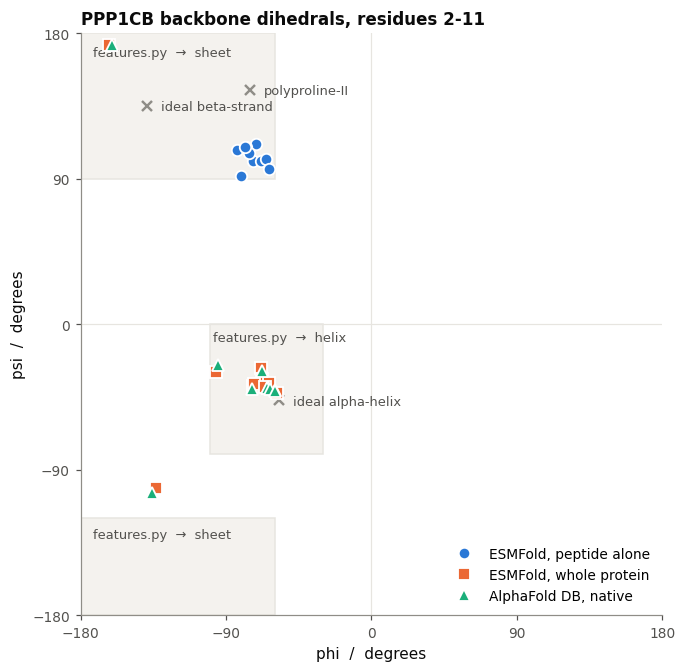

mean dihedrals and spread per source (residues 2-11)
source            phi     sd      psi     sd   in helix box / in sheet box
ESM-seg         -73.7    6.7    103.7    6.4    0 / 10  of 10
ESM-whole       -86.3   34.7    -21.2   71.5    8 /  1  of 10
AFDB            -84.4   35.7    -22.6   72.1    8 /  1  of 10


In [16]:
HELIX_BOX = (-100, -30, -80, 0)
SHEET_BOXES = [(-180, -60, 90, 180), (-180, -60, -180, -120)]
REFERENCES = {"ideal alpha-helix": (-57, -47), "polyproline-II": (-75, 145), "ideal beta-strand": (-139, 135)}

torsions = {s: dihedrals(backbone(SOURCE_DIR[s] / "generated" / "structures" / "PPP1CB.pdb"))
            for s in SOURCE_ORDER}

fig, ax = plt.subplots(figsize=(6.4, 6.0), constrained_layout=True)
for x0, x1, y0, y1 in SHEET_BOXES:
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, facecolor="#f4f2ee", edgecolor=GRID, lw=1.0, zorder=0))
x0, x1, y0, y1 = HELIX_BOX
ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, facecolor="#f4f2ee", edgecolor=GRID, lw=1.0, zorder=0))
ax.text(-172, 172, "features.py  →  sheet", color=INK_2, fontsize=8.5, va="top")
ax.text(-172, -126, "features.py  →  sheet", color=INK_2, fontsize=8.5, va="top")
ax.text(-98, -4, "features.py  →  helix", color=INK_2, fontsize=8.5, va="top")

for name, (phi, psi) in REFERENCES.items():
    ax.plot(phi, psi, marker="x", ms=7, mew=1.6, color=INK_3, zorder=2)
    ax.annotate(name, (phi, psi), textcoords="offset points", xytext=(9, -3),
                fontsize=8.5, color=INK_2, zorder=2)

for source in SOURCE_ORDER:
    data = torsions[source]
    ax.plot(data["phi"], data["psi"], linestyle="none", marker=SOURCE_MARKER[source], ms=7.5,
            mfc=SOURCE_COLOR[source], mec=SURFACE, mew=1.2, label=SOURCE_LABEL[source], zorder=3)

ax.set_xlim(-180, 180); ax.set_ylim(-180, 180); ax.set_aspect("equal")
ax.set_xticks(range(-180, 181, 90)); ax.set_yticks(range(-180, 181, 90))
ax.axhline(0, color=GRID, lw=0.8, zorder=1); ax.axvline(0, color=GRID, lw=0.8, zorder=1)
ax.set_xlabel("phi  /  degrees"); ax.set_ylabel("psi  /  degrees")
ax.set_title("PPP1CB backbone dihedrals, residues 2-11")
ax.legend(loc="lower right")
plt.show()

print("mean dihedrals and spread per source (residues 2-11)")
print(f"{'source':<12}{'phi':>9}{'sd':>7}{'psi':>9}{'sd':>7}   in helix box / in sheet box")
for source in SOURCE_ORDER:
    data = torsions[source]
    in_helix = ((data["phi"].between(*HELIX_BOX[:2])) & (data["psi"].between(*HELIX_BOX[2:]))).sum()
    in_sheet = sum(((data["phi"].between(bx[0], bx[1])) & (data["psi"].between(bx[2], bx[3]))).sum()
                   for bx in SHEET_BOXES)
    print(f"{SOURCE_SHORT[source]:<12}{data['phi'].mean():>9.1f}{data['phi'].std(ddof=1):>7.1f}"
          f"{data['psi'].mean():>9.1f}{data['psi'].std(ddof=1):>7.1f}   {in_helix:>2d} / {in_sheet:>2d}  of {len(data)}")

### Figure 2 — the graph the model received

Each cell is a residue pair; a filled cell is an 8 Å Cα–Cα contact, i.e. an edge in
`edge_index`. Blue cells are the chain itself (`|i − j| ≤ 2`, present in any peptide of
any shape); orange cells are everything that actually encodes a fold.

The left panel is the degeneracy: a width-2 band and nothing else. Any straight
12-residue object — a hand-drawn stick, an idealised PPII helix — produces a
bit-identical edge set, so those 42 directed edges tell the network only "a chain of
twelve". And because the segment-alone fold is PPII, which rises 3.1 Å per residue, the
first off-band diagonal misses the cutoff by less than an ångström: Cα(i, i+3) = 9.25 Å
against a 8.0 Å threshold.

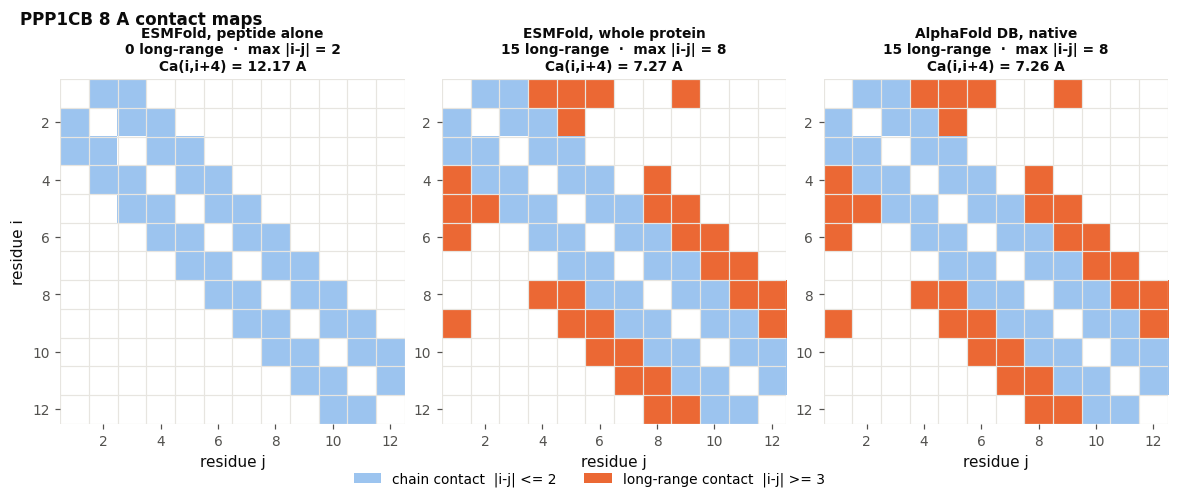

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(10.6, 4.0), constrained_layout=True)
CONTACT_CMAP = ListedColormap([SURFACE, "#9cc4ef", "#eb6834"])

for ax, source in zip(axes, SOURCE_ORDER):
    _, ca_coords, _ = parse_pdb(str(SOURCE_DIR[source] / "generated" / "structures" / "PPP1CB.pdb"))
    n = len(ca_coords)
    distances = np.linalg.norm(ca_coords[:, None] - ca_coords[None, :], axis=-1)
    offsets = np.abs(np.subtract.outer(np.arange(n), np.arange(n)))
    contact = (distances < DISTANCE_THRESHOLD) & (offsets > 0)
    grid = np.where(contact & (offsets >= 3), 2, np.where(contact, 1, 0))
    ax.imshow(grid, cmap=CONTACT_CMAP, vmin=0, vmax=2, origin="upper",
              extent=(0.5, n + 0.5, n + 0.5, 0.5), interpolation="nearest")
    ax.set_xticks(range(2, n + 1, 2)); ax.set_yticks(range(2, n + 1, 2))
    ax.set_xticks(np.arange(0.5, n + 1.5), minor=True); ax.set_yticks(np.arange(0.5, n + 1.5), minor=True)
    ax.grid(which="minor", color=GRID, lw=0.8); ax.tick_params(which="minor", length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    row = frame[(frame["source"] == source) & (frame["id"] == "PPP1CB")].iloc[0]
    ax.set_title(f"{SOURCE_LABEL[source]}\n{row.lr_edges} long-range  ·  max |i-j| = {row.max_sep}"
                 f"\nCa(i,i+4) = {row.ca_i4:.2f} A", fontsize=9, color=INK, loc="center")
    ax.set_xlabel("residue j")
axes[0].set_ylabel("residue i")
fig.legend(handles=[Patch(facecolor="#9cc4ef", label="chain contact  |i-j| <= 2"),
                    Patch(facecolor="#eb6834", label="long-range contact  |i-j| >= 3")],
           loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.07))
fig.suptitle("PPP1CB 8 A contact maps", x=0.012, y=1.04, ha="left", fontsize=11,
             fontweight="semibold", color=INK)
plt.show()

### What the right structure was worth

The two context-aware folds agree to within rounding — 15 long-range contacts each,
Cα(i,i+4) of 7.27 vs 7.26 Å, four `i→i+4` H-bonds each. ESMFold given the whole protein
independently reproduces AlphaFold's native helix, so the PPII rod was never an ESMFold
deficiency; it was missing context. That also means the two columns are a genuine
replicate of each other rather than two guesses.

Against that, the prediction moved **+0.21 σ**, 1.900 → 2.112, or **+0.010 P(AMP)**,
0.968 → 0.978 — from a graph with no structural content whatsoever to a correct native
helix, without approaching a decision boundary it was already far on the right side of.

## All 14 peptides

Same three measurements per peptide. `PPP1CB` is not the only one that changes, and one
peptide changes in the opposite direction.

In [18]:
def geometry_table() -> pd.DataFrame:
    pieces = {}
    for source in SOURCE_ORDER:
        block = common[common["source"] == source].set_index("id")
        short = SOURCE_SHORT[source]
        pieces[(short, "LR")] = block["lr_edges"]
        pieces[(short, "i->i+4")] = block["hb_i4"]
        pieces[(short, "Ca(i,i+4)")] = block["ca_i4"].round(2)
    table = pd.DataFrame(pieces).loc[COMMON]
    table.columns = pd.MultiIndex.from_tuples(table.columns)
    labels = common[common["source"] == "esm_segment"].set_index("id")["label"].loc[COMMON]
    table.insert(0, ("", "true"), np.where(labels == 1, "AMP", "·"))
    return table


print("LR = long-range contacts (|i-j| >= 3)   i->i+4 = Kabsch-Sander alpha H-bonds\n")
print(geometry_table().to_string())

LR = long-range contacts (|i-j| >= 3)   i->i+4 = Kabsch-Sander alpha H-bonds

                 ESM-seg                  ESM-whole                  AFDB                 
            true      LR i->i+4 Ca(i,i+4)        LR i->i+4 Ca(i,i+4)   LR i->i+4 Ca(i,i+4)
id                                                                                        
DFNA5        AMP      23      5      8.15        29      0     11.35   29      0     11.34
DCTN4        AMP      24      7      7.99         3      0     11.10    2      0     12.40
RPL41        AMP      21      9      6.32        21     10      6.30   21      9      6.40
PSMG2        AMP      25      9      8.16        29     11      7.59   30     11      7.60
GLB1         AMP      25     11      7.04        24      8      7.13   24      9      7.10
RPS4X        AMP      19      7      6.43        23      5      5.92   23      5      5.96
PPP1CB       AMP       0      0     12.17        15      4      7.27   15      4      7.26
CHMP2A      

In [19]:
summary = []
baseline = common[common["source"] == "esm_segment"].set_index("id").loc[COMMON]
for source in SOURCE_ORDER:
    block = common[common["source"] == source].set_index("id").loc[COMMON]
    summary.append({
        "source": SOURCE_LABEL[source],
        "accuracy": f"{block['correct'].mean() * 100:.1f}%  ({int(block['correct'].sum())}/{len(block)})",
        "degenerate graphs": int((block["max_sep"] <= 2).sum()),
        "mean long-range": f"{block['lr_edges'].mean():.1f}",
        "mean |dsigma| vs seg": f"{(block['sigma'] - baseline['sigma']).abs().mean():.4f}",
        "max |dsigma| vs seg": f"{(block['sigma'] - baseline['sigma']).abs().max():.4f}",
        "call flips vs seg": int((block["prediction"] != baseline["prediction"]).sum()),
    })
print(pd.DataFrame(summary).set_index("source").to_string())

errors = {SOURCE_SHORT[s]: sorted(common[(common["source"] == s) & ~common["correct"]]["id"])
          for s in SOURCE_ORDER}
print("\nmisclassified:")
for short, ids in errors.items():
    print(f"  {short:<10} {', '.join(ids)}")

whole = common[common["source"] == "esm_whole"].set_index("id").loc[COMMON]
native = common[common["source"] == "afdb_native"].set_index("id").loc[COMMON]
print("\nhow closely do the two context-aware sources agree with each other?")
print(f"  long-range contacts   r = {np.corrcoef(whole['lr_edges'], native['lr_edges'])[0, 1]:.4f}   "
      f"mean |diff| {(whole['lr_edges'] - native['lr_edges']).abs().mean():.2f}, max {int((whole['lr_edges'] - native['lr_edges']).abs().max())}")
print(f"  mean Ca(i,i+4)        mean |diff| {(whole['ca_i4'] - native['ca_i4']).abs().mean():.3f} A, "
      f"max {(whole['ca_i4'] - native['ca_i4']).abs().max():.3f} A")
print(f"  sigma                 mean |diff| {(whole['sigma'] - native['sigma']).abs().mean():.4f}, "
      f"max {(whole['sigma'] - native['sigma']).abs().max():.4f}")
print(f"  identical calls       {int((whole['prediction'] == native['prediction']).sum())}/{len(whole)}")
print(f"  for reference, peptide-alone vs native: r = "
      f"{np.corrcoef(baseline['lr_edges'], native['lr_edges'])[0, 1]:.4f}, "
      f"mean |diff| {(baseline['lr_edges'] - native['lr_edges']).abs().mean():.2f} contacts, "
      f"{(baseline['ca_i4'] - native['ca_i4']).abs().mean():.3f} A")

                               accuracy  degenerate graphs mean long-range mean |dsigma| vs seg max |dsigma| vs seg  call flips vs seg
source                                                                                                                                
ESMFold, peptide alone  100.0%  (14/14)                  1            18.1               0.0000              0.0000                  0
ESMFold, whole protein   92.9%  (13/14)                  0            22.1               0.1806              0.4422                  1
AlphaFold DB, native     92.9%  (13/14)                  0            22.0               0.1934              0.4423                  1

misclassified:
  ESM-seg    
  ESM-whole  DFNA5
  AFDB       DFNA5

how closely do the two context-aware sources agree with each other?
  long-range contacts   r = 0.9973   mean |diff| 0.57, max 3
  mean Ca(i,i+4)        mean |diff| 0.154 A, max 1.302 A
  sigma                 mean |diff| 0.0293, max 0.2939
  identical cal

## Calibration is not neutral here

σ is a property of the model and the structure in front of it. P(AMP) and the call are a
property of the **calibration**, and this checkpoint ships two. The same three structure
sources scored under its Platt file are still on disk, which makes the comparison direct:
the margins are bit-identical and only the threshold moves, from σ = 0 to σ = +0.78.

That one change reverses which protocol looks better. Under temperature the peptide-alone
run is the only one that gets all 14 right, and the single disagreement is `DFNA5`, which
the native fold pushes *below* the line. Under Platt the peptide-alone run was the worst
of the three and the single disagreement was `RPS4X`, which the native fold pushed *above*
it. Neither ordering survives the other calibration — which is the honest reading of an
accuracy column that is one peptide wide.

In [20]:
platt_runs = {source: resolve_run(source, "platt") for source in SOURCE_ORDER}
platt = pd.concat([pd.read_csv(platt_runs[source] / "sequence_predictions.csv").assign(source=source)
                   for source in SOURCE_ORDER], ignore_index=True)
platt = platt[platt["id"].isin(COMMON)]

margin_drift = max(
    float((common[common["source"] == s].set_index("id").loc[COMMON, "sigma"]
           - platt[platt["source"] == s].set_index("id").loc[COMMON, "sigma"]).abs().max())
    for s in SOURCE_ORDER)
print(f"largest |sigma difference| between the temperature and Platt runs: {margin_drift:.2e}")
print(f"  threshold   temperature {SIGMA_THRESHOLD:+.4f}   platt {PLATT_THRESHOLD:+.4f}\n")

rows = []
for source in SOURCE_ORDER:
    warm = common[common["source"] == source].set_index("id").loc[COMMON]
    cold = platt[platt["source"] == source].set_index("id").loc[COMMON]
    cold_correct = (cold["prediction"] == 1) == (cold["label"] == 1)
    rows.append({
        "source": SOURCE_LABEL[source],
        "temperature": f"{int(warm['correct'].sum())}/{len(warm)}",
        "platt": f"{int(cold_correct.sum())}/{len(cold)}",
        "calls that differ": ", ".join(sorted(warm.index[warm["prediction"] != cold["prediction"]])) or "none",
    })
print(pd.DataFrame(rows).set_index("source").to_string())

base_warm = common[common["source"] == "esm_segment"].set_index("id").loc[COMMON]
base_cold = platt[platt["source"] == "esm_segment"].set_index("id").loc[COMMON]
print("\nwhich peptide changes its call when the structure changes?")
for source in SOURCE_ORDER[1:]:
    warm = common[common["source"] == source].set_index("id").loc[COMMON]
    cold = platt[platt["source"] == source].set_index("id").loc[COMMON]
    print(f"  {SOURCE_SHORT[source]:<10} temperature: "
          f"{', '.join(warm.index[warm['prediction'] != base_warm['prediction']]) or 'none':<10}"
          f"   platt: {', '.join(cold.index[cold['prediction'] != base_cold['prediction']]) or 'none'}")

largest |sigma difference| between the temperature and Platt runs: 0.00e+00
  threshold   temperature +0.0000   platt +0.7781

                       temperature  platt         calls that differ
source                                                             
ESMFold, peptide alone       14/14  10/14  DFNA5, ETS1, GLB1, RPS4X
ESMFold, whole protein       13/14  11/14                ETS1, GLB1
AlphaFold DB, native         13/14  11/14                ETS1, GLB1

which peptide changes its call when the structure changes?
  ESM-whole  temperature: DFNA5        platt: RPS4X
  AFDB       temperature: DFNA5        platt: RPS4X


### Figure 3 — σ distributions

The question is how much the score distribution moves when the structure underneath it is
replaced. Panel **a** overlays the three; panel **b** tracks each peptide individually,
because an unchanged distribution is not by itself evidence that nothing moved — offsetting
shifts would look the same.

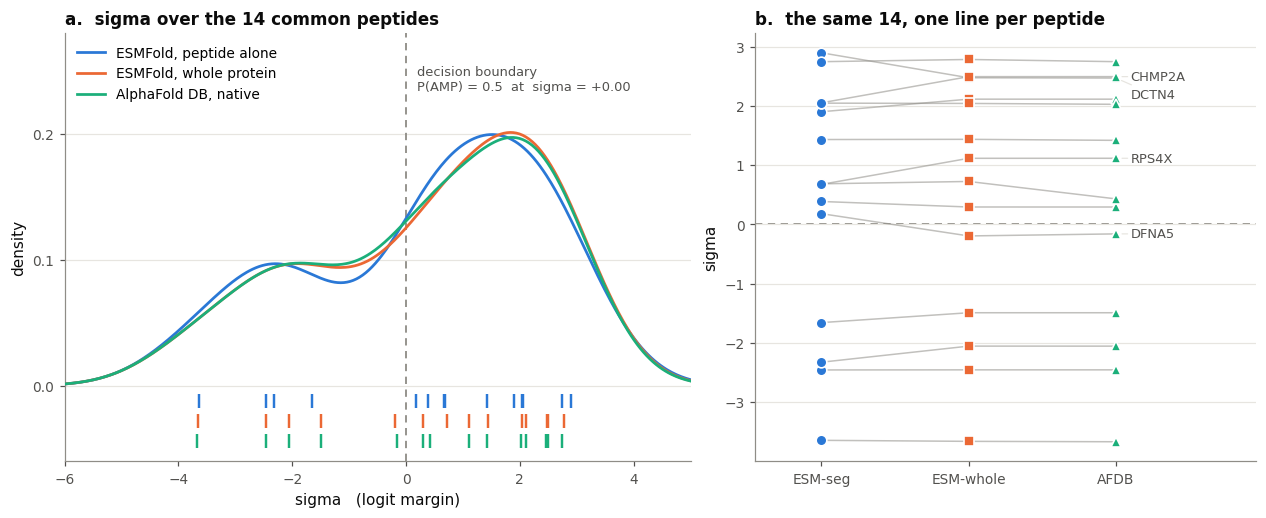

In [21]:
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(11.4, 4.6), constrained_layout=True,
                                 gridspec_kw={"width_ratios": [1.25, 1.0]})
grid_x = np.linspace(-6, 5, 400)

for source in SOURCE_ORDER:
    values = common.loc[common["source"] == source, "sigma"].to_numpy()
    ax_a.plot(grid_x, gaussian_kde(values, bw_method=0.45)(grid_x), color=SOURCE_COLOR[source],
              lw=1.8, label=SOURCE_LABEL[source], zorder=3)
for offset, source in enumerate(SOURCE_ORDER):
    values = common.loc[common["source"] == source, "sigma"].to_numpy()
    ax_a.plot(values, np.full_like(values, -0.012 - 0.016 * offset), linestyle="none", marker="|",
              ms=9, mew=1.6, color=SOURCE_COLOR[source], zorder=3)

ax_a.axvline(SIGMA_THRESHOLD, color=INK_3, lw=1.2, ls=(0, (4, 3)), zorder=2)
ax_a.annotate(f"decision boundary\nP(AMP) = 0.5  at  sigma = {SIGMA_THRESHOLD:+.2f}",
              (SIGMA_THRESHOLD, 0.255), textcoords="offset points", xytext=(7, 0),
              fontsize=8.5, color=INK_2, va="top")
ax_a.set_xlim(-6, 5); ax_a.set_ylim(-0.06, 0.28)
ax_a.set_yticks([0, 0.1, 0.2])
ax_a.grid(axis="y", zorder=0)
ax_a.set_xlabel("sigma   (logit margin)"); ax_a.set_ylabel("density")
ax_a.set_title("a.  sigma over the 14 common peptides")
ax_a.legend(loc="upper left")

positions = {source: i for i, source in enumerate(SOURCE_ORDER)}
wide = common.pivot(index="id", columns="source", values="sigma").loc[COMMON]
labels = common[common["source"] == "esm_segment"].set_index("id")["label"].loc[COMMON]
for peptide in COMMON:
    series = [wide.loc[peptide, s] for s in SOURCE_ORDER]
    ax_b.plot(list(positions.values()), series, color=INK_3, lw=1.0, alpha=0.55, zorder=2)
    for source, value in zip(SOURCE_ORDER, series):
        ax_b.plot(positions[source], value, marker=SOURCE_MARKER[source], ms=7, mfc=SOURCE_COLOR[source],
                  mec=SURFACE, mew=1.1, zorder=3)
drift = (wide["afdb_native"] - wide["esm_segment"]).abs()
labelled = drift.sort_values(ascending=False).index[:4]
placed: list[float] = []
for peptide in sorted(labelled, key=lambda p: -wide.loc[p, "afdb_native"]):
    y_text = wide.loc[peptide, "afdb_native"]
    while placed and y_text > placed[-1] - 0.30:  # push down until the labels clear each other
        y_text = placed[-1] - 0.30
    placed.append(y_text)
    ax_b.annotate(peptide, (2, wide.loc[peptide, "afdb_native"]), xytext=(2.1, y_text),
                  fontsize=8.5, color=INK_2, va="center",
                  arrowprops=dict(arrowstyle="-", lw=0.8, color=GRID, shrinkA=0, shrinkB=4))
ax_b.axhline(SIGMA_THRESHOLD, color=INK_3, lw=1.2, ls=(0, (4, 3)), zorder=1)
ax_b.set_xticks(list(positions.values()), [SOURCE_SHORT[s] for s in SOURCE_ORDER])
ax_b.set_xlim(-0.45, 2.95); ax_b.grid(axis="y", zorder=0)
ax_b.set_ylabel("sigma"); ax_b.set_title("b.  the same 14, one line per peptide")
plt.show()

In [22]:
spread = []
for source in SOURCE_ORDER:
    values = common.loc[common["source"] == source, "sigma"]
    amp = common.loc[(common["source"] == source) & (common["label"] == 1), "sigma"]
    non = common.loc[(common["source"] == source) & (common["label"] == 0), "sigma"]
    pooled = np.sqrt(((len(amp) - 1) * amp.var(ddof=1) + (len(non) - 1) * non.var(ddof=1))
                     / (len(amp) + len(non) - 2))
    spread.append({
        "source": SOURCE_LABEL[source],
        "sd": f"{values.std(ddof=1):.3f}", "IQR": f"{values.quantile(.75) - values.quantile(.25):.3f}",
        "range": f"{values.max() - values.min():.3f}",
        "min": f"{values.min():+.3f}", "max": f"{values.max():+.3f}",
        "mean AMP": f"{amp.mean():+.3f}", "mean non-AMP": f"{non.mean():+.3f}",
        "class gap": f"{amp.mean() - non.mean():+.3f}", "gap / pooled sd": f"{(amp.mean() - non.mean()) / pooled:.3f}",
    })
print("sigma spread, 14 common peptides (10 AMP / 4 non-AMP)\n")
print(pd.DataFrame(spread).set_index("source").to_string())

sigma spread, 14 common peptides (10 AMP / 4 non-AMP)

                           sd    IQR  range     min     max mean AMP mean non-AMP class gap gap / pooled sd
source                                                                                                     
ESMFold, peptide alone  2.091  3.208  6.540  -3.645  +2.895   +1.499       -2.522    +4.021           4.270
ESMFold, whole protein  2.081  3.262  6.444  -3.662  +2.782   +1.527       -2.416    +3.943           3.966
AlphaFold DB, native    2.074  3.250  6.414  -3.669  +2.745   +1.493       -2.418    +3.911           3.880


### Figure 4 — absolute σ per peptide, against the threshold

What decides a call is where σ sits relative to the decision boundary, not how far it
moved, so this plots the absolute score with the threshold on the same axis; the span bar
carries the movement and the Δ columns are printed underneath. The structure effect is
real but small against the distance most peptides sit from the line — only `DFNA5` ends up
close enough for the choice of fold to decide its call.

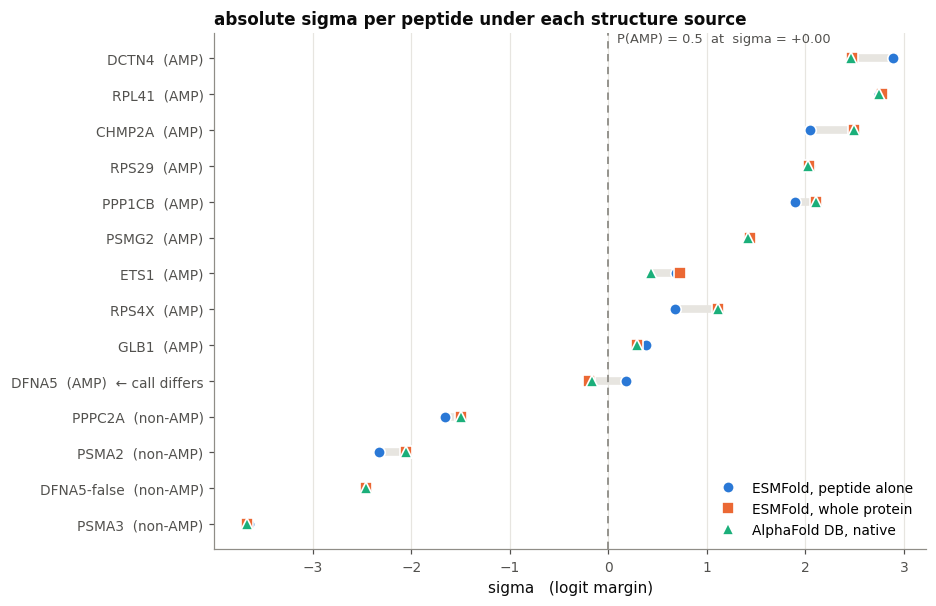

id               true  sigma seg  sigma whole  sigma AFDB  dsigma whole  dsigma AFDB
DCTN4             AMP    +2.8946      +2.4731     +2.4681       -0.4215      -0.4265
RPL41             AMP    +2.7443      +2.7817     +2.7446       +0.0375      +0.0004
CHMP2A            AMP    +2.0499      +2.4921     +2.4922       +0.4422      +0.4423
RPS29             AMP    +2.0448      +2.0398     +2.0252       -0.0051      -0.0197
PPP1CB            AMP    +1.8997      +2.1120     +2.1118       +0.2123      +0.2120
PSMG2             AMP    +1.4307      +1.4342     +1.4168       +0.0035      -0.0139
ETS1              AMP    +0.6833      +0.7232     +0.4293       +0.0399      -0.2540
RPS4X             AMP    +0.6735      +1.1139     +1.1144       +0.4403      +0.4409
GLB1              AMP    +0.3855      +0.2922     +0.2921       -0.0933      -0.0935
DFNA5             AMP    +0.1799      -0.1962     -0.1615       -0.3761      -0.3414
PPPC2A              ·    -1.6587      -1.4922     -1.4922       +

In [23]:
order = wide["esm_segment"].sort_values().index.tolist()
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(8.4, 5.4), constrained_layout=True)

span_low = wide.loc[order, SOURCE_ORDER].min(axis=1)
span_high = wide.loc[order, SOURCE_ORDER].max(axis=1)
ax.hlines(y, span_low, span_high, color=GRID, lw=5, zorder=1)
for source in SOURCE_ORDER:
    ax.plot(wide.loc[order, source], y, linestyle="none", marker=SOURCE_MARKER[source], ms=7.5,
            mfc=SOURCE_COLOR[source], mec=SURFACE, mew=1.1, label=SOURCE_LABEL[source], zorder=3)

ax.axvline(SIGMA_THRESHOLD, color=INK_3, lw=1.2, ls=(0, (4, 3)), zorder=2)
ax.annotate(f"P(AMP) = 0.5  at  sigma = {SIGMA_THRESHOLD:+.2f}", (SIGMA_THRESHOLD, len(order) - 0.45),
            textcoords="offset points", xytext=(6, 0), fontsize=8.5, color=INK_2, va="center")
labels = common[common["source"] == "esm_segment"].set_index("id")["label"]
disagree = [p for p in order if wide.loc[p, SOURCE_ORDER].gt(SIGMA_THRESHOLD).nunique() > 1]
ticks = [f"{p}  ({'AMP' if labels[p] == 1 else 'non-AMP'})" + ("  \u2190 call differs" if p in disagree else "")
         for p in order]
ax.set_yticks(y, ticks)
ax.set_ylim(-0.7, len(order) - 0.3); ax.grid(axis="x", zorder=0)
ax.set_xlabel("sigma   (logit margin)")
ax.set_title("absolute sigma per peptide under each structure source")
ax.legend(loc="lower right")
plt.show()

print(f"{'id':<13}{'true':>8}{'sigma seg':>11}{'sigma whole':>13}{'sigma AFDB':>12}"
      f"{'dsigma whole':>14}{'dsigma AFDB':>13}")
for peptide in reversed(order):
    row = wide.loc[peptide]
    print(f"{peptide:<13}{'AMP' if labels[peptide] == 1 else chr(183):>8}"
          f"{row['esm_segment']:>+11.4f}{row['esm_whole']:>+13.4f}{row['afdb_native']:>+12.4f}"
          f"{row['esm_whole'] - row['esm_segment']:>+14.4f}{row['afdb_native'] - row['esm_segment']:>+13.4f}")

## What this set shows

**The two context-aware sources behave as replicates of each other.** Across the 14
peptides their long-range contact counts correlate at r = 0.997 (mean difference 0.6
contacts, worst 3), mean Cα(i,i+4) differs by 0.15 Å on average, σ by 0.029, and they
make the same call on 14/14. The peptide-alone fold against the native one is r = 0.81,
7.4 contacts and 1.76 Å. On `PPP1CB` the two agree exactly: 15 long-range contacts, four
`i→i+4` H-bonds, Cα(i,i+4) of 7.27 against 7.26 Å.

They are not interchangeable everywhere. `DCTN4` is the worst case — 3 long-range
contacts against 2, and Cα(i,i+4) of 11.10 Å against 12.40 Å — and `ETS1` is where they
disagree most in score, Δσ = 0.29, enough to move it from a +0.04 shift to a −0.25 one.
With that caveat, folding a peptide's parent with ESMFold is a usable substitute for
fetching the AFDB model, which matters because AFDB coverage is a lookup that can miss
and ESMFold is not.

**Folding a peptide alone is what produced the degenerate graph**, not ESMFold itself.
One of 14 peptides had a structurally empty graph under the peptide-alone protocol and
none did under either context-aware protocol. `DCTN4` shows the mirror-image failure:
folded alone it invents a compact fold with 24 long-range contacts where both
context-aware methods give an extended segment with 2–3, so the peptide-alone protocol
both destroys real structure and manufactures structure that is not there.

**The predictions barely follow.** Mean |Δσ| is 0.18–0.19 against a class separation of
~3.9 σ, mean |ΔP(AMP)| is 0.027–0.032, and the σ distribution is nearly unchanged in every
spread statistic: sd 2.091 → 2.081 → 2.074, IQR 3.21 → 3.26 → 3.25, range 6.54 → 6.44 →
6.41. Exactly one of 14 peptides changes its call — `DFNA5`, and it is the whole of the
100% → 92.9% accuracy difference. This checkpoint's decisions are carried by sequence and
the QSAR descriptors; the structural branch contributes almost nothing.

**That is not a wiring fault in this checkpoint.** `gnn_scaled_combined_dataset` is the
schema-3 model: `edge_feature_dim = 3`, so `edge_attr` — and with it the Cα distance of
every edge — does reach each `GATConv` through `lin_edge`, and `geo_bn` normalises the
tabular block. The distances are plumbed in and the model still does not lean on them.

## Caveats worth keeping attached to these numbers

- **14 peptides, 4 of them negatives, and the accuracy difference is one row wide.** It
  is also calibration-dependent: swapping temperature scaling for this checkpoint's Platt
  file, which changes no margin at all, moves the single disagreement from `DFNA5` to
  `RPS4X` and reverses which protocol looks better. Nothing here supports a claim about
  which protocol is more accurate. The claim is about the *size* of the structural effect,
  which is what the σ shifts measure and which no calibration changes.
- **All three runs use a checkpoint trained on peptide-alone structures.** B and C are
  inference-time distribution shifts. A model whose training graphs were degenerate in the
  same way has no reason to have learned to use the structure channel, so this measures
  the trained model's sensitivity, not the ceiling on what structure could contribute.
  The fair test is retraining on context-aware folds.
- **`fraction_sheet` is wrong but inert.** It is one of the 20 `Geo` columns, and this
  checkpoint's `feature_set` is `QSAR` (12 columns, verified against both
  `model_summary.json` and the fitted `tabular_scaler.joblib`). Fixing the secondary
  structure call changes no number in this notebook. It would matter to a `Geo` or
  `Combined` run, and the spurious-sheet rate is drift-asymmetric: 8.2% of training rows
  against 85.7% of the 1k proteome candidates.